# XXZ模型：VQE

XXZ模型の基底エネルギー$E_0$を、VQEで求める。以下ではQiskitで回路を組み、状態ベクトルシミュレータで計算する。手法の一般論は [methods/04_vqe.ipynb](../../methods/04_vqe.ipynb)、模型の定義は [00_model.ipynb](00_model.ipynb) を参照。以下では、[03_trotter.ipynb](03_trotter.ipynb)と同じく偶数ボンドと奇数ボンドに分け、さらに$XY$項と$ZZ$項に分けて

\begin{equation}
H = H_{\mathrm{even}}^{XY} + H_{\mathrm{even}}^{ZZ} + H_{\mathrm{odd}}^{XY} + H_{\mathrm{odd}}^{ZZ},\quad
H_{\mathrm{even}}^{XY} = J\sum_{j\,\text{偶数}}(X_jX_{j+1} + Y_jY_{j+1}),\quad H_{\mathrm{even}}^{ZZ} = J\Delta\sum_{j\,\text{偶数}}Z_jZ_{j+1}
\end{equation}

と書く（奇数ボンドも同様）。

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# 厳密対角化（src/qmb/ed.py）と XXZ 模型の定義（src/qmb/models.py）
from qmb.ed import ground_state
from qmb.models import xxz_hamiltonian as hamiltonian
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

# XXZ 模型の VQE（src/qmb/circuits.py）
#   xxz_op          : H を Pauli 演算子の和（SparsePauliOp）で表したもの
#   neel_circuit    : Néel 状態 |0101...> を作る回路
#   singlet_circuit : 偶数ボンドに一重項を並べた状態を作る回路
#   xxz_hva_circuit : Hamiltonian Variational Ansatz（local=True でゲートごとのパラメータ）
#   energy, xxz_vqe : エネルギー期待値 E(θ) と、層を1つずつ増やす VQE
# 実装を見たいときは、Jupyterで関数名の後に ?? を付けて実行する（例: xxz_hva_circuit??）
from qmb.circuits import xxz_op, neel_circuit, singlet_circuit, xxz_hva_circuit, energy, xxz_vqe

## 1. アンザッツ：一重項から始めるHamiltonian Variational Ansatz

TFIMのHVAは、$H_X$の基底状態$\ket{+\cdots+}$から出発し、$H$の部分の指数関数を交互にかけた（[01_tfim/04_vqe.ipynb](../01_tfim/04_vqe.ipynb)）。XXZ模型でも同じ考え方で、**偶数ボンドの部分$H_{\mathrm{even}} = H_{\mathrm{even}}^{XY} + H_{\mathrm{even}}^{ZZ}$の基底状態**から出発する。偶数ボンドは互いに重ならないので、その基底状態はボンドごとの基底状態の積であり、[01_exact_diag.ipynb](01_exact_diag.ipynb)の手計算より、各ボンドの基底状態は$\Delta>-1$で一重項である。
\begin{equation}
\ket{\psi_0} = \ket{s}_{0,1}\otimes\ket{s}_{2,3}\otimes\cdots,\quad \ket{s} = \frac{\ket{01} - \ket{10}}{\sqrt{2}}
\end{equation}
一重項は、各ボンドで$X\to H\to\mathrm{CNOT}\to X$の4つのゲートで作れる（`singlet_circuit`）。

この状態に、4つの部分の指数関数を交互に$p$層かける。
\begin{equation}
\ket{\psi(\boldsymbol{\theta})} = \prod_{l=1}^{p}\left(e^{-i\theta_{l,4}H_{\mathrm{even}}^{XY}}e^{-i\theta_{l,3}H_{\mathrm{even}}^{ZZ}}e^{-i\theta_{l,2}H_{\mathrm{odd}}^{XY}}e^{-i\theta_{l,1}H_{\mathrm{odd}}^{ZZ}}\right)\ket{\psi_0}
\end{equation}
パラメータは$4p$個である（R. Wiersema et al., PRX Quantum 1, 020319 (2020) で使われた形）。各指数関数は[03_trotter.ipynb](03_trotter.ipynb)と同じく$R_{XX}R_{YY}$や$R_{ZZ}$のゲートで厳密に書ける。最初の状態が$H_{\mathrm{even}}$の固有状態なので、各層は奇数ボンドから始める。

- **対称性を保つ**：一重項は全磁化$\sum_jZ_j = 0$の状態で、どのゲートも全磁化を保存するので、出力状態は常に基底状態と同じ$\sum_jZ_j = 0$の部分空間にある。VQEで探す空間が、$2^n$次元から$\binom{n}{n/2}$次元に自動的に絞られる。
- **局所的なHVA**：TFIMと同じく、各ゲートに別々のパラメータを持たせたもの（パラメータは$2p\times$ボンドの数）も試す。前者を「一様なHVA」、後者を「局所的なHVA」と呼ぶ。
- **周期境界条件**：ボンド$(n-1, 0)$も奇数ボンドとして加える（$n$は偶数）。

## 2. エネルギーの測定

$E = J\sum_j\left(\langle X_jX_{j+1}\rangle + \langle Y_jY_{j+1}\rangle + \Delta\langle Z_jZ_{j+1}\rangle\right)$のうち

- $Z_jZ_{j+1}$の項はすべて$Z$基底の測定1種類
- $X_jX_{j+1}$の項はすべての量子ビットに$H$ゲートをかけた$X$基底の測定1種類
- $Y_jY_{j+1}$の項はすべての量子ビットに$S^\dagger$と$H$をかけた$Y$基底の測定1種類

で求まる。したがって、**3種類の測定**ですべての項が求まる（TFIMは2種類だった）。$Z$基底の測定では、全磁化$\sum_jZ_j$が0でないショットは雑音によるものなので、捨てる（ポストセレクション）こともできる。

## 3. $n=2$の手計算

$n=2$（開放境界）の場合を手で計算する。

- **有効1スピンへの帰着**

  [03_trotter.ipynb](03_trotter.ipynb)の手計算と同じく、全磁化0の部分空間$\{\ket{01}, \ket{10}\}$で$\ket{01}$を$\ket{0}$、$\ket{10}$を$\ket{1}$とみなすと
  $$
  X_0X_1 = Y_0Y_1 = \sigma_x,\quad Z_0Z_1 = -1,\quad H = 2J\sigma_x - J\Delta
  $$
  である。基底状態は$\sigma_x = -1$の$\ket{-}_{\mathrm{eff}} = \frac{\ket{01} - \ket{10}}{\sqrt{2}}$（一重項）で、$E_0 = -2J - J\Delta$である。

- **一重項から始めた場合**

  初期状態が一重項そのものなので、$p=0$（パラメータなし）で厳密な基底状態である。$n=2$ではボンドが偶数ボンドの1本だけなので、HVAの各層$e^{-i\theta H_{\mathrm{even}}^{XY}} = e^{-2i\theta J\sigma_x}$、$e^{-i\theta H_{\mathrm{even}}^{ZZ}} = e^{i\theta J\Delta}$は一重項に位相をつけるだけで、**どのパラメータでも**$E = E_0$になる。

- **Néel状態から始めた場合（うまくいかない例）**

  比較のため、Néel状態$\ket{01} = \ket{0}_{\mathrm{eff}}$から同じ形のアンザッツを作ってみる。$e^{-i\theta H^{XY}} = e^{-2i\theta J\sigma_x}$は有効スピンを$x$軸まわりに回し、$e^{-i\theta H^{ZZ}}$は位相をつけるだけである。$z$方向を向いた状態を$x$軸まわりに何度回しても、Blochベクトルは$y$-$z$平面から出ないので$\langle\sigma_x\rangle = 0$のままである。したがって
  $$
  E(\boldsymbol{\theta}) = 2J\langle\sigma_x\rangle - J\Delta = -J\Delta
  $$
  と、**パラメータによらず一定**で、$E_0 = -2J - J\Delta$には届かない。

  これは[methods/04_vqe.ipynb](../../methods/04_vqe.ipynb)の2.1節で$R_x(\theta)\ket{0}$が$E_0$に届かなかったのと同じ状況である。一重項の$\ket{01}$と$\ket{10}$の相対的な**符号**（$-1$）は、$XY$項による回転（相対位相$\mp i$を作る）と$ZZ$項（$\ket{01}$と$\ket{10}$に同じ位相をつける）だけでは作れない。初期状態の選び方がアンザッツの表現力を決めることがわかる。

## 4. コードで確かめる

Qiskitで回路を組んで計算する。回路を作る関数は `src/qmb/circuits.py` にまとめてあり、ノートブック冒頭で読み込んでいる。

In [2]:
# 例: N=2, J=1, Δ=0.5
N = 2
J = 1.0
Delta = 0.5
H_op = xxz_op(N, J, Delta)
E0 = ground_state(hamiltonian(N, J, Delta))[0]
print(f"基底エネルギー E0 (厳密)   = {E0:.6f}  (手計算: -J(2+Δ) = {-J * (2 + Delta):.6f})")

# 一重項から始める HVA（p=1）: どのパラメータでも E = E0
qc = xxz_hva_circuit(N, J, Delta, p=1)
print(qc.draw())
rng = np.random.default_rng(0)
E_singlet = [energy(qc, H_op, rng.uniform(-np.pi, np.pi, qc.num_parameters)) for _ in range(5)]
print("一重項 + HVA, ランダムなパラメータでの E =", np.round(E_singlet, 6))

基底エネルギー E0 (厳密)   = -2.500000  (手計算: -J(2+Δ) = -2.500000)
     ┌───┐┌───┐                     ┌──────────────┐┌──────────────┐
q_0: ┤ X ├┤ H ├──■────────■─────────┤0             ├┤0             ├
     └───┘└───┘┌─┴─┐┌───┐ │ZZ(θ[2]) │  Rxx(2*θ[3]) ││  Ryy(2*θ[3]) │
q_1: ──────────┤ X ├┤ X ├─■─────────┤1             ├┤1             ├
               └───┘└───┘           └──────────────┘└──────────────┘
一重項 + HVA, ランダムなパラメータでの E = [-2.5 -2.5 -2.5 -2.5 -2.5]


                  ┌───────────┐┌───────────┐
q_0: ──────■──────┤0          ├┤0          ├
     ┌───┐ │ZZ(γ) │  Rxx(2*β) ││  Ryy(2*β) │
q_1: ┤ X ├─■──────┤1          ├┤1          ├
     └───┘        └───────────┘└───────────┘
γ=0.0: E の最小値 = -0.500000, 最大値 = -0.500000  (手計算: -JΔ = -0.5)
γ=0.7: E の最小値 = -0.500000, 最大値 = -0.500000  (手計算: -JΔ = -0.5)


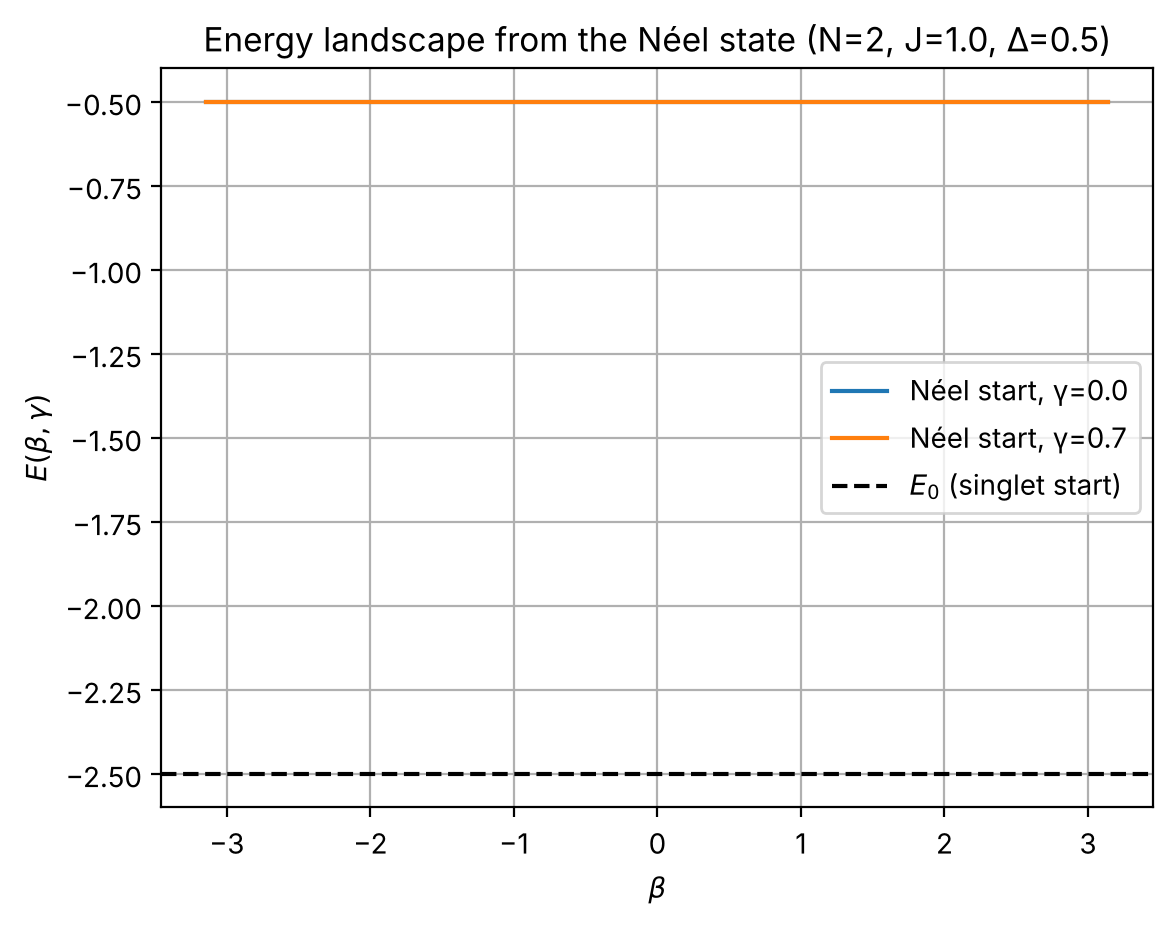

In [3]:
# Néel 状態から始めた場合: e^{-iθ H^XY} と e^{-iθ' H^ZZ} を交互にかけても E = -JΔ のまま
from qiskit.circuit import Parameter

beta, gamma = Parameter("β"), Parameter("γ")
qc_neel = neel_circuit(N)
qc_neel.rzz(2 * J * Delta * gamma, 0, 1)   # e^{-iγ H^ZZ}
qc_neel.rxx(2 * J * beta, 0, 1)            # e^{-iβ H^XY} = R_XX(2Jβ) R_YY(2Jβ)
qc_neel.ryy(2 * J * beta, 0, 1)
print(qc_neel.draw())

betas = np.linspace(-np.pi, np.pi, 101)
for g in [0.0, 0.7]:
    E_neel = [energy(qc_neel, H_op, [b, g]) for b in betas]   # パラメータの順は (β, γ)
    print(f"γ={g}: E の最小値 = {min(E_neel):.6f}, 最大値 = {max(E_neel):.6f}  (手計算: -JΔ = {-J * Delta})")
    plt.plot(betas, E_neel, label=f"Néel start, γ={g}")
plt.axhline(E0, color="k", ls="--", label=r"$E_0$ (singlet start)")
plt.xlabel(r"$\beta$")
plt.ylabel(r"$E(\beta, \gamma)$")
plt.title(f"Energy landscape from the Néel state (N={N}, J={J}, Δ={Delta})")
plt.legend()
plt.grid()
plt.show()

一重項から始めるとどのパラメータでも$E_0$になり、Néel状態から始めるとパラメータによらず$E = -J\Delta$のままで、どちらも手計算と一致した。

$n$を大きくしたときに層の数$p$がいくつ必要か（一様なHVAと局所的なHVA、周期境界条件と開放境界条件の比較）は、[11_ground_state.ipynb](11_ground_state.ipynb)で調べる。

---
**前へ**: [03 Trotter分解](03_trotter.ipynb)